# TP5 — Partie B.1 : Bases de LangGraph

LangChain fournit des briques de haut niveau (`create_agent`) ; **LangGraph** est le framework *bas niveau* d'orchestration : on modélise explicitement l'application comme un **graphe d'états** :

| Concept | Rôle |
|---|---|
| **State** | structure de données partagée (TypedDict) : l'instantané courant de l'application |
| **Node** | fonction Python `state → mise à jour de l'état` |
| **Edge** | transition entre nœuds : fixe, **conditionnelle** (routage) ou en **boucle** |
| **Reducer** | règle de fusion d'un champ de l'état (ex. `add_messages` ajoute au lieu d'écraser) |
| **Checkpointer** | sauvegarde de l'état par `thread_id` → mémoire, reprise, human-in-the-loop |

Plan : 1) graphe simple · 2) branche conditionnelle · 3) boucle · 4) agent ReAct avec tools · 5) streaming · 6) mémoire · 7) human-in-the-loop · 8) système multi-agents (superviseur).

In [1]:
from typing import TypedDict, Literal, Sequence, Annotated
from IPython.display import Image, Markdown, display
from langgraph.graph import StateGraph, START, END
from langchain.messages import AnyMessage, HumanMessage, AIMessage, SystemMessage


def afficher_graphe(graph):
    """Affiche le graphe compilé (PNG via mermaid.ink, sinon code Mermaid)."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

## 1. Graphe simple : State → Node → Edges

**1- État** : un `TypedDict` avec une liste de messages et un compteur.

In [2]:
class SimpleGraphState(TypedDict):
    messages: Sequence[AnyMessage]
    counter: int

**2- Nœud** : il lit l'état, ajoute un `AIMessage` (la requête inversée en majuscules) et met à jour le compteur.

In [3]:
def graph_node(state: SimpleGraphState) -> SimpleGraphState:
    """Reverse the string input"""
    query = state["messages"][-1].content
    reponse = AIMessage(content=f"Agent Response to query : [{query}], Output : {query.upper()[::-1]}")
    return {"messages": state["messages"] + [reponse], "counter": 10}

**3- Compilation** : `START → node → END`, puis **4- visualisation**.

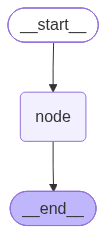

In [4]:
workflow = StateGraph(SimpleGraphState)
workflow.add_node("node", graph_node)
workflow.add_edge(START, "node")
workflow.add_edge("node", END)
graph = workflow.compile()
afficher_graphe(graph)

**5- Invocation** : le nœud reçoit l'état initial et renvoie l'état mis à jour.

In [5]:
resp = graph.invoke({"messages": [HumanMessage("My Name is Mohamed")]})
print("counter =", resp["counter"])
for message in resp["messages"]:
    message.pretty_print()

counter = 10
================================ Human Message =================================

My Name is Mohamed
================================== Ai Message ==================================

Agent Response to query : [My Name is Mohamed], Output : DEMAHOM SI EMAN YM


## 2. Branche conditionnelle (`add_conditional_edges`)

Un nœud d'analyse écrit une **décision** dans l'état ; une fonction de **routage** lit cette décision et choisit le chemin suivant.

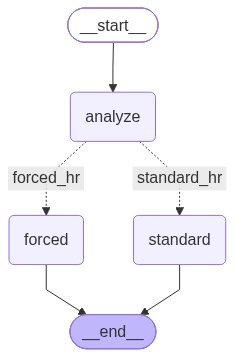

In [6]:
# 1) État partagé du workflow
class EmployeeState(TypedDict):
    name: str
    age: int
    salary: float
    decision: Literal["standard_hr", "forced_hr"]
    result: str


# 2) Nœud de vérification
def analyze_employee(state: EmployeeState) -> EmployeeState:
    if state["age"] <= 30 and state["salary"] <= 40000:
        state["decision"] = "standard_hr"
    else:
        state["decision"] = "forced_hr"
    return state


# 3) Chemin 1
def standard_hr_process(state: EmployeeState) -> EmployeeState:
    state["result"] = f"Demande de {state['name']} envoyée au traitement RH standard"
    return state


# 4) Chemin 2
def forced_hr_validation(state: EmployeeState) -> EmployeeState:
    state["result"] = f"Demande de {state['name']} envoyée à la validation RH forcée"
    return state


# 5) Fonction de routage conditionnel
def router(state: EmployeeState):
    return state["decision"]


wf = StateGraph(EmployeeState)
wf.add_node("analyze", analyze_employee)
wf.add_node("standard", standard_hr_process)
wf.add_node("forced", forced_hr_validation)
wf.add_edge(START, "analyze")
wf.add_conditional_edges("analyze", router, {"standard_hr": "standard", "forced_hr": "forced"})
wf.add_edge("standard", END)
wf.add_edge("forced", END)
graph = wf.compile()
afficher_graphe(graph)

In [7]:
print(graph.invoke({"name": "Mohamed", "age": 23, "salary": 20000}))
print(graph.invoke({"name": "Yassine", "age": 55, "salary": 65000}))

{'name': 'Mohamed', 'age': 23, 'salary': 20000, 'decision': 'standard_hr', 'result': 'Demande de Mohamed envoyée au traitement RH standard'}
{'name': 'Yassine', 'age': 55, 'salary': 65000, 'decision': 'forced_hr', 'result': 'Demande de Yassine envoyée à la validation RH forcée'}


## 3. Graphe avec boucle

Le dossier administratif est vérifié ; tant qu'il manque des documents, on **notifie** l'employé puis on **revient** à la vérification (arête `employee_notification → file_verification`).

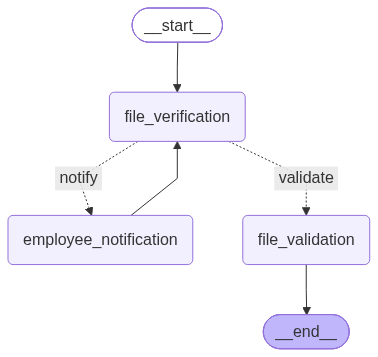

In [8]:
class AdministrativeFileState(TypedDict):
    name: str
    remaining_documents: int
    reminders: int
    status: Literal["incomplete", "complete", "validated"]


def verify_employee_file(state: AdministrativeFileState):
    state["status"] = "incomplete" if state["remaining_documents"] > 0 else "complete"
    print(f"Vérification du dossier de {state['name']} → statut : {state['status']}")
    return state


def notify_employee(state: AdministrativeFileState):
    state["reminders"] += 1
    if state["remaining_documents"] > 0:
        state["remaining_documents"] -= 1
    print(f"   Relance n°{state['reminders']} → documents restants : {state['remaining_documents']}")
    return state


def validate_file(state: AdministrativeFileState):
    state["status"] = "validated"
    print(f"✅ Dossier de {state['name']} validé")
    return state


def router(state: AdministrativeFileState) -> Literal["notify", "validate"]:
    return "notify" if state["status"] == "incomplete" else "validate"


workflow = StateGraph(AdministrativeFileState)
workflow.add_node("file_verification", verify_employee_file)
workflow.add_node("employee_notification", notify_employee)
workflow.add_node("file_validation", validate_file)
workflow.set_entry_point("file_verification")
workflow.add_conditional_edges("file_verification", router,
                               {"notify": "employee_notification", "validate": "file_validation"})
workflow.add_edge("employee_notification", "file_verification")
workflow.add_edge("file_validation", END)
graph = workflow.compile()
afficher_graphe(graph)

In [9]:
resp = graph.invoke({"name": "Mohamed", "remaining_documents": 4, "reminders": 0})
print(resp)

Vérification du dossier de Mohamed → statut : incomplete
   Relance n°1 → documents restants : 3
Vérification du dossier de Mohamed → statut : incomplete
   Relance n°2 → documents restants : 2
Vérification du dossier de Mohamed → statut : incomplete
   Relance n°3 → documents restants : 1
Vérification du dossier de Mohamed → statut : incomplete
   Relance n°4 → documents restants : 0
Vérification du dossier de Mohamed → statut : complete
✅ Dossier de Mohamed validé
{'name': 'Mohamed', 'remaining_documents': 0, 'reminders': 4, 'status': 'validated'}
